# 01 — Raycast Survival Arena: Interactive Deep RL Guide

Welcome to the companion engineering & Machine Learning notebook for **Project 01 (`01_rl_raycast_arena`)** in **AI Game Studio**.

Instead of duplicating simulation or neural network code inside a monolithic notebook, this guide imports directly from our clean, `<= 250`-line production modules in `src/sim/` and `src/ai/` so you can:
1. **Understand the Physics & 32-Ray Doppler LiDAR Math** visually.
2. **Inspect the Exact `133`-Dimensional Neural Input Tensor** the AI perceives.
3. **Verify the Dueling Double-DQN Bellman Update** step by step.
4. **Prove Episode-by-Episode Improvement** across 450 episodes (Reward, Cores Harvested, Wall/Mine Crash Rates, and $Q$-Value Stability).
5. **Compare Stages `[1]`–`[4]` Head-to-Head** with 2D flight trajectories—matching keys **`1`, `2`, `3`, `4`** in the live Pygame telemetry window (`python -m src.main --eval`).

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.sim.entities import Action, AgentState, ArenaConfig, HitType, advance_agent_kinematics
from src.sim.raycast import build_observation, cast_sensor_rays, extract_danger_proximity
from src.sim.arena_env import RaycastArenaEnv
from src.ai.q_network import QNetwork
from src.ai.dqn_agent import DQNAgent, DQNConfig
from src.ai.trainer import HISTORY_FILENAME, MILESTONE_SPECS, TrainingHistory

plt.style.use("dark_background")
plt.rcParams["figure.dpi"] = 120
cfg = ArenaConfig()
print(f"Loaded ArenaConfig | Observation Dim: {cfg.observation_dim} | Actions: {cfg.action_dim}")

Loaded ArenaConfig | Observation Dim: 133 | Actions: 6


---
## Chapter 1 — Inertial Quadcopter Kinematics & Symmetric Action Space

Unlike grid-world games where an agent teleports cell-by-cell, our **Scout Drone** obeys inertial 2D kinematics inside an $800 \times 600$ arena (`src/sim/entities.py`):

$$\theta_{t+1} = \text{wrap}\!\left(\theta_t + u_{\text{turn}} \cdot \omega\right), \qquad \mathbf{v}_{t+1} = \left(\mathbf{v}_t + u_{\text{thrust}} \cdot a_{\text{thrust}} \begin{bmatrix}\cos\theta_{t+1} \\ \sin\theta_{t+1}\end{bmatrix}\right) \cdot d_{\text{drag}}$$

With $a_{\text{thrust}} = 0.85\text{ px/tick}^2$ and linear drag $d_{\text{drag}} = 0.84$:
* **Steady-State Top Speed**: $v_{\text{ss}} = \frac{0.85 \times 0.84}{1 - 0.84} \approx 4.46\text{ px/tick}$ ($\approx 268\text{ px/s}$ at 60 FPS).
* **Coasting Braking Distance**: $\approx 23.4\text{ px}$—meaning the drone skids with real momentum if it enters a corner or approaches a moving mine too fast!

Let's simulate 35 ticks of each of the **6 symmetric discrete actions** starting with forward momentum to see the drone's maneuvering envelope:

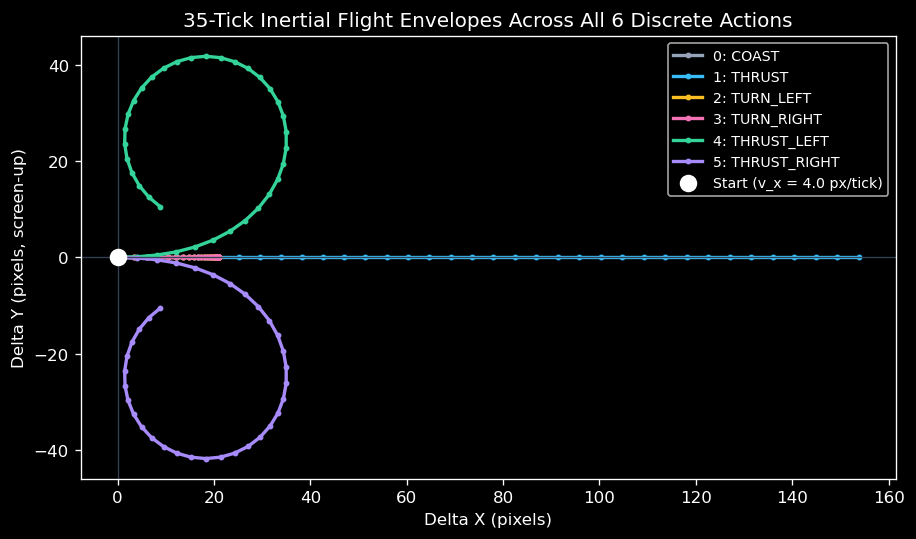

In [2]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = ["#94a3b8", "#38bdf8", "#fbbf24", "#f472b6", "#34d399", "#a78bfa"]

for action in Action:
    drone = AgentState(
        position=np.array([0.0, 0.0], dtype=np.float32),
        velocity=np.array([4.0, 0.0], dtype=np.float32),
        heading=0.0,
    )
    trail = [drone.position.copy()]
    for _ in range(35):
        advance_agent_kinematics(drone, int(action), cfg)
        trail.append(drone.position.copy())
    pts = np.stack(trail)
    ax.plot(pts[:, 0], -pts[:, 1], marker="o", markersize=2.5, linewidth=2, color=colors[int(action)], label=f"{int(action)}: {action.name}")

ax.scatter([0], [0], s=90, color="white", zorder=5, label="Start (v_x = 4.0 px/tick)")
ax.set_title("35-Tick Inertial Flight Envelopes Across All 6 Discrete Actions")
ax.set_xlabel("Delta X (pixels)")
ax.set_ylabel("Delta Y (pixels, screen-up)")
ax.axhline(0, color="#334155", linewidth=0.8)
ax.axvline(0, color="#334155", linewidth=0.8)
ax.legend(loc="best", fontsize=8.5)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()

---
## Chapter 2 — 32-Ray LiDAR & Doppler Closing-Velocity Perception

Why don't we feed raw $(x, y)$ coordinates of every mine into the neural network?
1. **Fixed Input Size Regardless of Map Complexity**: Whether there are 3 mines or 15 mines, a 32-ray LiDAR sweep always produces the exact same input shape.
2. **Egocentric Body-Frame Invariance**: `Ray 0` always points straight out of the drone's nose ($\theta$). Dodging a mine on your left looks mathematically identical whether you are flying North, East, South, or West.
3. **Solving Single-Frame "Snapshot Blindness" (Doppler Range-Rate)**: From a single freeze-frame of distances, it is impossible to tell whether a red mine is moving *toward* you or *away* from you. By appending the per-ray obstacle closing speed $\Delta\text{proximity}_t = \text{clip}\big(15 \cdot (\text{danger}_t - \text{danger}_{t-1}), -1, 1\big)$, our `133`-float observation turns a partially observable problem into a full Markov state:

$$\mathbf{s}_t = \underbrace{\text{WallProx}_{32} \;\|\; \text{HazardProx}_{32} \;\|\; \text{CoreProx}_{32}}_{\text{96 Occluded LiDAR Channels}} \;\|\; \underbrace{\Delta\text{Danger}_{32}}_{\text{32 Doppler Velocities}} \;\|\; \underbrace{[v_{\text{fwd}}, v_{\text{lat}}, \cos\Delta\phi, \sin\Delta\phi, d_{\text{core}}]}_{\text{5 Body-Frame & Compass Features}} \in \mathbb{R}^{133}$$

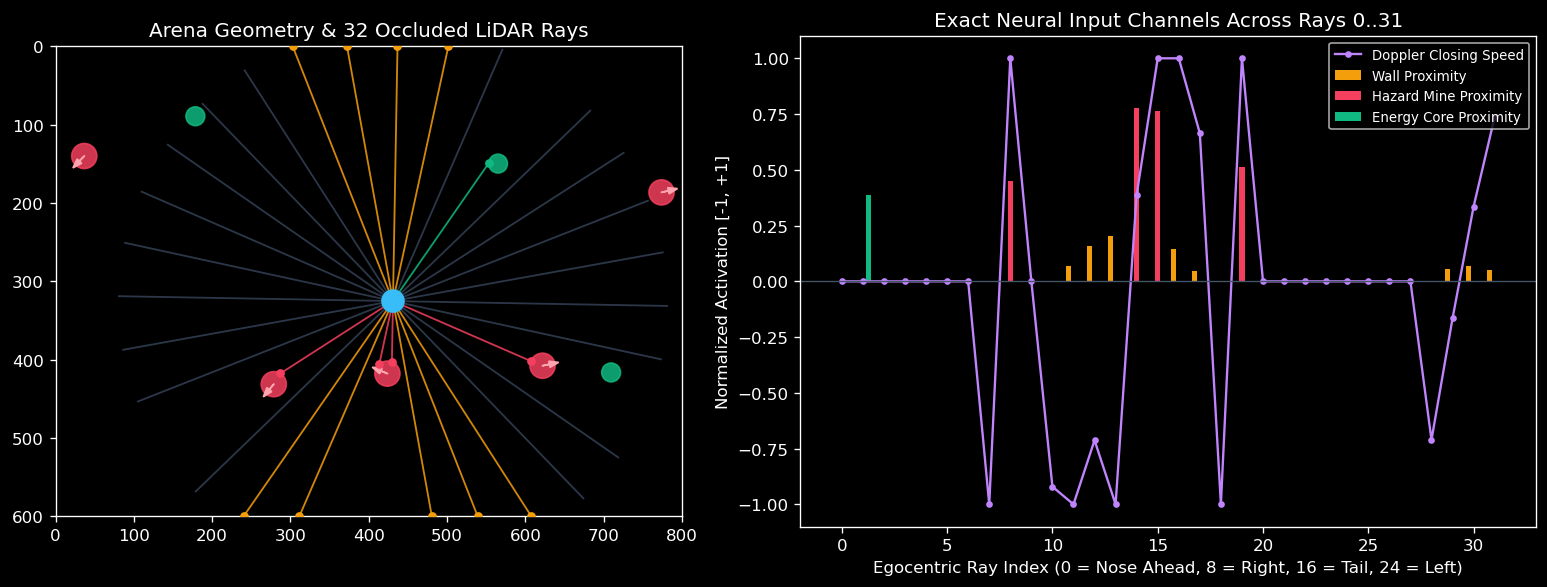

In [3]:
env = RaycastArenaEnv(cfg, seed=14)
obs = env.reset(seed=14)
for _ in range(18):
    obs = env.step(int(Action.THRUST_LEFT)).observation
snap = env.get_snapshot()

fig, (ax_map, ax_vec) = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.15, 1.35]})

ray_palette = {
    int(HitType.NONE): "#334155",
    int(HitType.WALL): "#f59e0b",
    int(HitType.HAZARD): "#f43f5e",
    int(HitType.CORE): "#10b981",
}
ox, oy = snap.agent.position
for idx in range(cfg.num_rays):
    ex, ey = snap.rays.endpoints[idx]
    ht = int(snap.rays.hit_types[idx])
    ax_map.plot([ox, ex], [oy, ey], color=ray_palette[ht], linewidth=1.1, alpha=0.85)
    if ht != int(HitType.NONE):
        ax_map.scatter([ex], [ey], color=ray_palette[ht], s=18, zorder=4)

for core in snap.cores:
    ax_map.add_patch(plt.Circle(core, cfg.core_radius, color="#10b981", alpha=0.85))
for haz, vel in zip(snap.hazards, env.hazard_velocities):
    ax_map.add_patch(plt.Circle(haz, cfg.hazard_radius, color="#f43f5e", alpha=0.85))
    ax_map.arrow(haz[0], haz[1], vel[0] * 12, vel[1] * 12, head_width=8, color="#fda4af", length_includes_head=True)

ax_map.add_patch(plt.Circle(snap.agent.position, cfg.agent_radius, color="#38bdf8", zorder=5))
ax_map.set_xlim(0, cfg.width)
ax_map.set_ylim(cfg.height, 0)
ax_map.set_aspect("equal")
ax_map.set_title("Arena Geometry & 32 Occluded LiDAR Rays")

ray_matrix = obs[:96].reshape(32, 3)
doppler = obs[96:128]
ray_ids = np.arange(32)
ax_vec.bar(ray_ids - 0.25, ray_matrix[:, 0], width=0.25, color="#f59e0b", label="Wall Proximity")
ax_vec.bar(ray_ids, ray_matrix[:, 1], width=0.25, color="#f43f5e", label="Hazard Mine Proximity")
ax_vec.bar(ray_ids + 0.25, ray_matrix[:, 2], width=0.25, color="#10b981", label="Energy Core Proximity")
ax_vec.plot(ray_ids, doppler, color="#c084fc", marker=".", linewidth=1.4, label="Doppler Closing Speed")
ax_vec.axhline(0, color="#475569", linewidth=0.8)
ax_vec.set_title("Exact Neural Input Channels Across Rays 0..31")
ax_vec.set_xlabel("Egocentric Ray Index (0 = Nose Ahead, 8 = Right, 16 = Tail, 24 = Left)")
ax_vec.set_ylabel("Normalized Activation [-1, +1]")
ax_vec.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

---
## Chapter 3 — Inside the Dueling Double-DQN Brain

Standard Deep Q-Learning suffers from two instabilities: **maximization bias** (using the same noisy weights to both pick and score the next action) and **action-agnostic danger estimation** (when a mine is $5\text{ px}$ away, *every* action is dangerous, so learning each action's value separately wastes data).

Our architecture in `src/ai/q_network.py` and `src/ai/dqn_agent.py` combines **Dueling Heads** with **Double-DQN Target Decoupling**:

$$Q_\theta(s, a) = \underbrace{V_\theta(s)}_{\text{State Safety / Value}} + \left(\underbrace{A_\theta(s, a) - \frac{1}{|\mathcal{A}|}\sum_{a'} A_\theta(s, a')}_{\text{Centered Maneuver Advantage}}\right)$$

$$a^* = \arg\max_{a'} Q_\theta(s_{t+1}, a'), \qquad y_t = r_t + \gamma (1 - \text{terminated}_t) \, Q_{\theta^-}(s_{t+1}, a^*)$$

Let's inspect the network parameter count and verify on a synthetic transition that our Bellman update drives TD loss smoothly to zero:

Dueling QNetwork (hidden=64) Parameters: 13,447 | Production (hidden=160) Parameters: 48,967


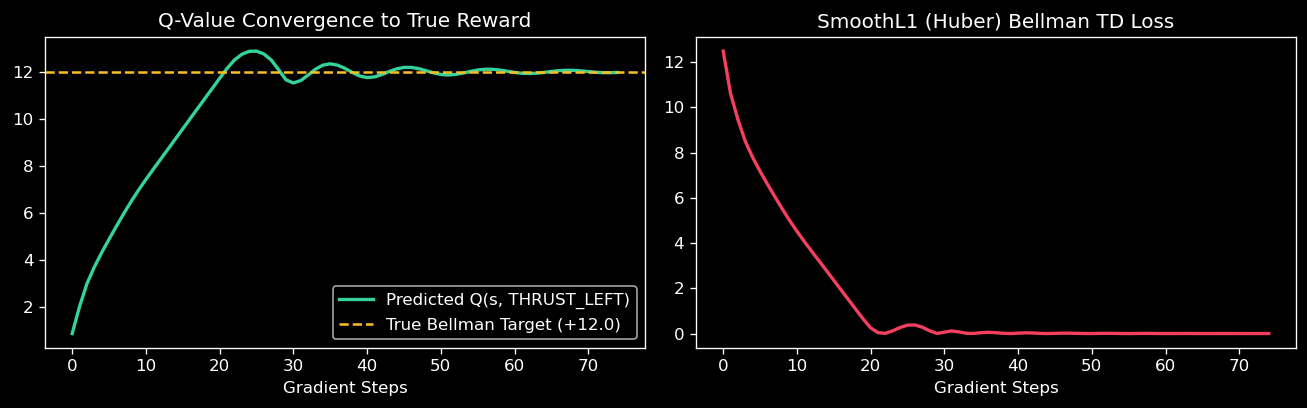

In [4]:
demo_cfg = DQNConfig(
    obs_dim=cfg.observation_dim,
    action_dim=cfg.action_dim,
    hidden_dim=64,
    learning_rate=4e-3,
    batch_size=16,
    warmup_steps=16,
    train_frequency=1,
    tau=0.15,
)
demo_agent = DQNAgent(demo_cfg, seed=7, device="cpu")
param_count = sum(p.numel() for p in demo_agent.online_net.parameters())
print(f"Dueling QNetwork (hidden=64) Parameters: {param_count:,} | Production (hidden=160) Parameters: {sum(p.numel() for p in QNetwork(133, 6, 160).parameters()):,}")

s_test = np.full(cfg.observation_dim, 0.2, dtype=np.float32)
s_next = np.zeros(cfg.observation_dim, dtype=np.float32)
td_losses, q_preds = [], []

for _ in range(90):
    loss = demo_agent.record_step(s_test, action=4, reward=12.0, next_state=s_next, terminated=True)
    if loss is not None:
        td_losses.append(loss)
        q_preds.append(float(demo_agent.select_action(s_test, greedy=True)[1][4]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(q_preds, color="#34d399", linewidth=2, label="Predicted Q(s, THRUST_LEFT)")
ax1.axhline(12.0, color="#fbbf24", linestyle="--", label="True Bellman Target (+12.0)")
ax1.set_title("Q-Value Convergence to True Reward")
ax1.set_xlabel("Gradient Steps")
ax1.legend()

ax2.plot(td_losses, color="#f43f5e", linewidth=2)
ax2.set_title("SmoothL1 (Huber) Bellman TD Loss")
ax2.set_xlabel("Gradient Steps")
plt.tight_layout()
plt.show()

---
## Chapter 4 — Proving Model Improvement as Episodes Increase

How do we **scientifically verify** that our model improves as episodes progress from `Episode 1` to `Episode 450`?

During training (`python -m src.main --headless --episodes 450`), `src/ai/trainer.py` logs every episode's metrics to `checkpoints/training_history.json` and runs **deterministic greedy evaluations** ($\epsilon = 0$) every 25 episodes on fixed unseen arena seeds. Look at all four diagnostic curves together:
1. **Reward Curve**: Both the 30-episode rolling training mean and greedy evaluation reward climb from **`-42` up past `+230`**.
2. **Cores Harvested**: Climbs from **`0.0` cores/episode** at Episode 0 up to **`10–13+` cores/episode**.
3. **Failure Mode Evolution**: Early in training (`Ep 1–40`), the drone dies mostly by slamming into **Walls (`~60%`)**. By Episode 75, **Wall Deaths drop to ~`0%`**, and as Doppler evasion matures, **Full 1,000-Step Survival rises steadily**.
4. **Value Estimation Health**: Mean predicted $\max_a Q(s, a)$ rises smoothly and plateaus cleanly around `+45..+55` without diverging!

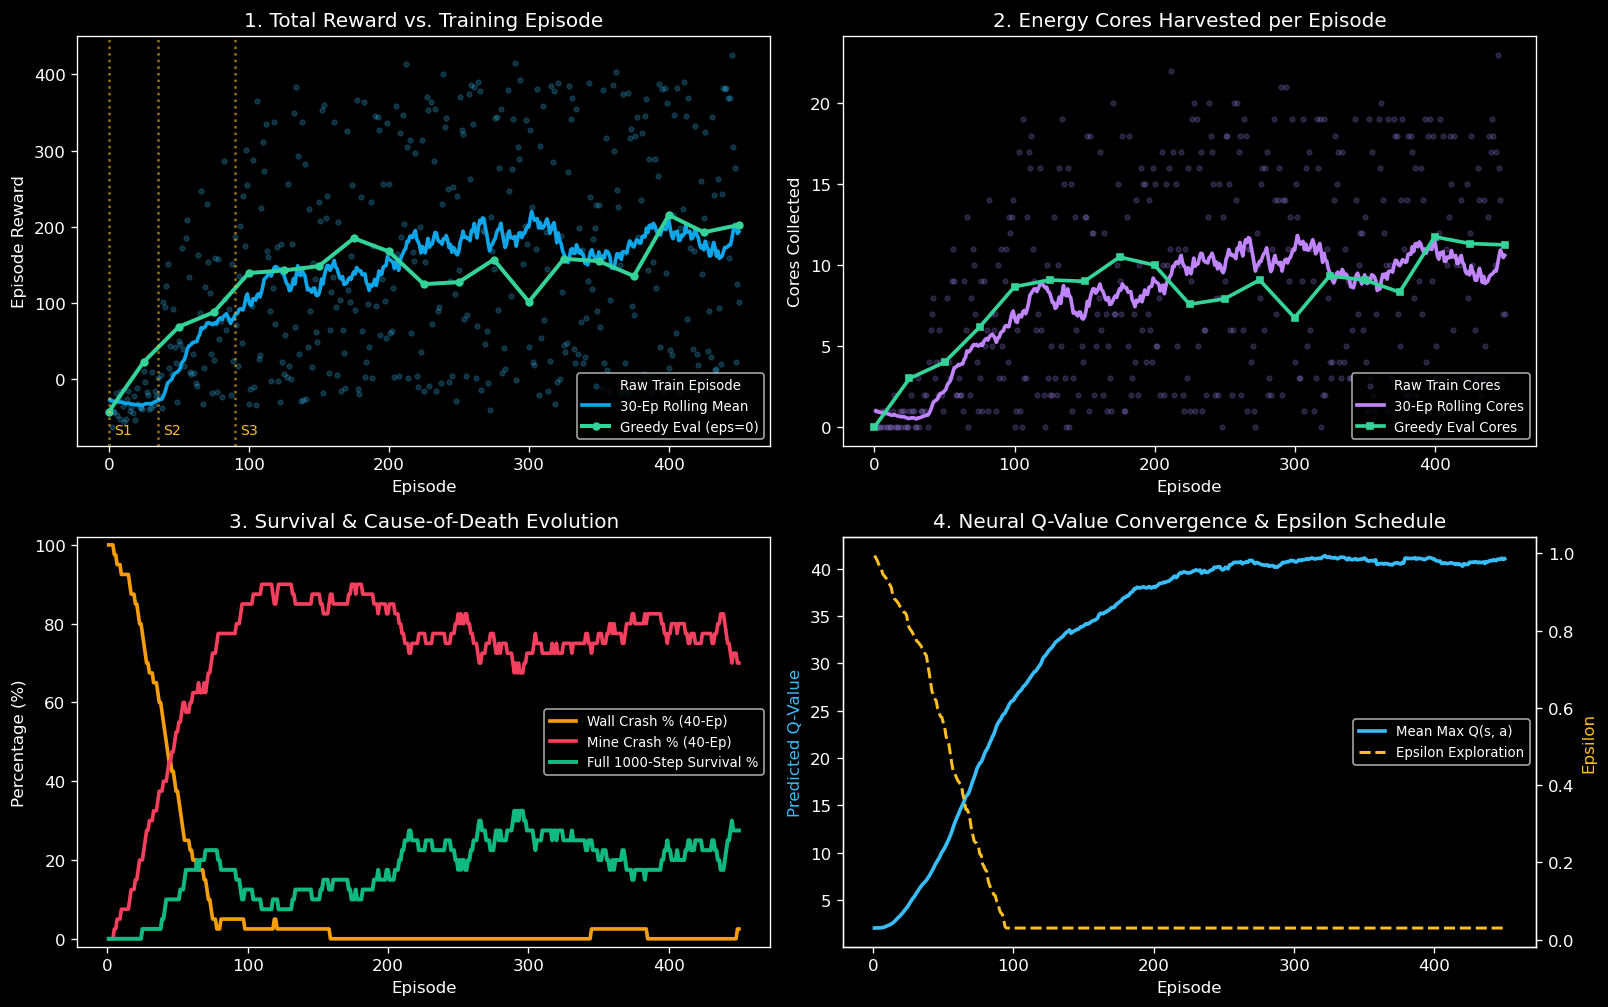

In [5]:
history_path = PROJECT_ROOT / "checkpoints" / HISTORY_FILENAME
history = TrainingHistory.load_json(history_path)

eps = np.array(history.episodes)
rewards = np.array(history.rewards)
cores = np.array(history.cores)
outcomes = np.array(history.outcomes)
mean_q = np.array(history.mean_q)
epsilons = np.array(history.epsilons)


def rolling_mean(arr: np.ndarray, window: int = 30) -> np.ndarray:
    kernel = np.ones(window) / window
    if len(arr) < window:
        return arr
    padded = np.pad(arr.astype(float), (window - 1, 0), mode="edge")
    return np.convolve(padded, kernel, mode="valid")


fig, axes = plt.subplots(2, 2, figsize=(13.5, 8.5))

ax = axes[0, 0]
ax.scatter(eps, rewards, s=8, alpha=0.22, color="#38bdf8", label="Raw Train Episode")
ax.plot(eps, rolling_mean(rewards, 30), color="#0ea5e9", linewidth=2.2, label="30-Ep Rolling Mean")
ax.plot(history.eval_episodes, history.eval_rewards, color="#34d399", marker="o", markersize=4, linewidth=2.4, label="Greedy Eval (eps=0)")
for m_ep, m_lbl in [(0, "S1"), (35, "S2"), (90, "S3")]:
    ax.axvline(m_ep, color="#fbbf24", linestyle=":", alpha=0.6)
    ax.text(m_ep + 4, ax.get_ylim()[0] + 15, m_lbl, color="#fbbf24", fontsize=8.5)
ax.set_title("1. Total Reward vs. Training Episode")
ax.set_xlabel("Episode")
ax.set_ylabel("Episode Reward")
ax.legend(loc="lower right", fontsize=8)

ax = axes[0, 1]
ax.scatter(eps, cores, s=8, alpha=0.20, color="#a78bfa", label="Raw Train Cores")
ax.plot(eps, rolling_mean(cores, 30), color="#c084fc", linewidth=2.2, label="30-Ep Rolling Cores")
ax.plot(history.eval_episodes, history.eval_cores, color="#34d399", marker="s", markersize=4, linewidth=2.2, label="Greedy Eval Cores")
ax.set_title("2. Energy Cores Harvested per Episode")
ax.set_xlabel("Episode")
ax.set_ylabel("Cores Collected")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1, 0]
wall_rate = rolling_mean((outcomes == "wall").astype(float) * 100.0, 40)
mine_rate = rolling_mean((outcomes == "mine").astype(float) * 100.0, 40)
surv_rate = rolling_mean((outcomes == "survived").astype(float) * 100.0, 40)
ax.plot(eps, wall_rate, color="#f59e0b", linewidth=2.2, label="Wall Crash % (40-Ep)")
ax.plot(eps, mine_rate, color="#f43f5e", linewidth=2.2, label="Mine Crash % (40-Ep)")
ax.plot(eps, surv_rate, color="#10b981", linewidth=2.4, label="Full 1000-Step Survival %")
ax.set_title("3. Survival & Cause-of-Death Evolution")
ax.set_xlabel("Episode")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(-2, 102)
ax.legend(loc="center right", fontsize=8)

ax = axes[1, 1]
ax.plot(eps, rolling_mean(mean_q, 20), color="#38bdf8", linewidth=2.2, label="Mean Max Q(s, a)")
ax_eps = ax.twinx()
ax_eps.plot(eps, epsilons, color="#fbbf24", linestyle="--", linewidth=1.8, label="Epsilon Exploration")
ax.set_title("4. Neural Q-Value Convergence & Epsilon Schedule")
ax.set_xlabel("Episode")
ax.set_ylabel("Predicted Q-Value", color="#38bdf8")
ax_eps.set_ylabel("Epsilon", color="#fbbf24")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax_eps.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="center right", fontsize=8)

plt.tight_layout()
plt.show()

---
## Chapter 5 — Evolutionary Milestone Showdown (`Stages [1]–[4]`)

In the live Pygame window (`python -m src.main --eval`), pressing keys **`1`**, **`2`**, **`3`**, and **`4`** hot-swaps four saved evolutionary brains on the fly:
* **`[1]` Stage 1 (`Ep 0 Untrained`)**: Random orthogonal weights.
* **`[2]` Stage 2 (`Ep 35 Novice`)**: Early wall awareness and first core approaches.
* **`[3]` Stage 3 (`Ep 90 Skilled`)**: Competent core harvesting with developing Doppler evasion.
* **`[4]` Stage 4 (`Champion best_dqn.pt`)**: Converged 32-ray Dueling-Doppler mastery.

Let's benchmark all 4 checkpoints across **50 unseen test arenas** and then plot their **exact 2D flight trajectories** on the same arena seed!

STAGE 1: EP 0 UNTRAINED    | Avg Reward:  -42.00 | Avg Cores:  0.06 | Avg Steps: 269.3/1000


STAGE 2: EP 35 NOVICE      | Avg Reward:  +55.36 | Avg Cores:  4.28 | Avg Steps: 533.5/1000


STAGE 3: EP 90 SKILLED     | Avg Reward:  +85.41 | Avg Cores:  5.66 | Avg Steps: 371.4/1000


STAGE 4: CHAMPION          | Avg Reward: +194.98 | Avg Cores: 10.72 | Avg Steps: 591.0/1000


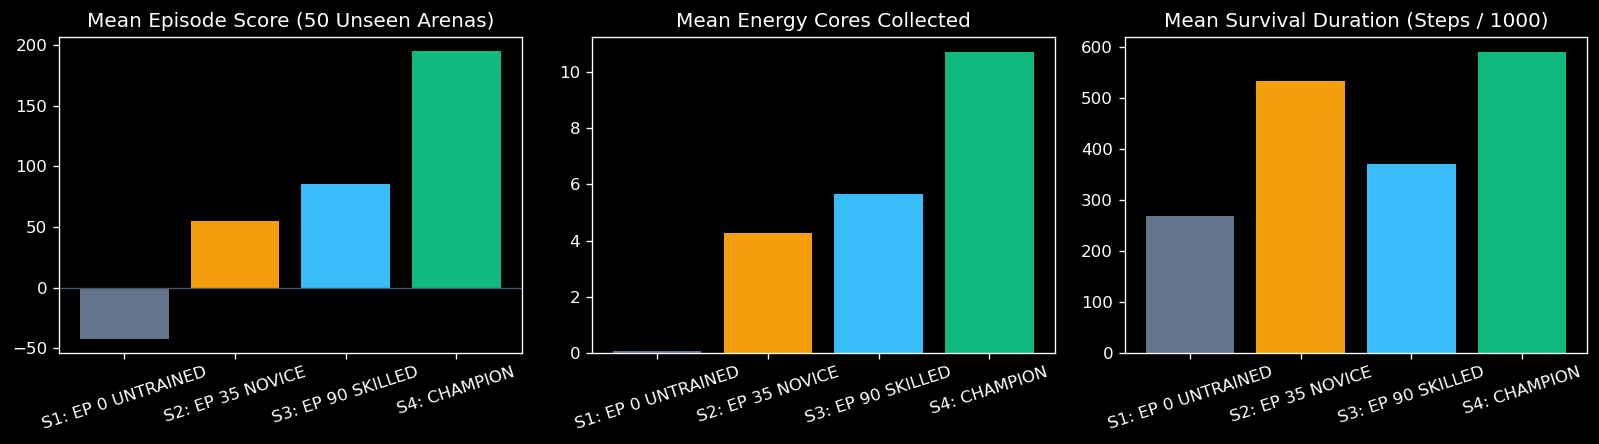

In [6]:
stage_names, stage_rewards, stage_cores, stage_steps = [], [], [], []
bench_env = RaycastArenaEnv(cfg, seed=70_000)
dqn_cfg = DQNConfig(obs_dim=cfg.observation_dim, action_dim=cfg.action_dim)

for stage_idx in (1, 2, 3, 4):
    fname, label = MILESTONE_SPECS[stage_idx]
    model = DQNAgent(dqn_cfg, seed=42, device="cpu")
    model.load_checkpoint(PROJECT_ROOT / "checkpoints" / fname)
    r_list, c_list, s_list = [], [], []
    for i in range(50):
        obs = bench_env.reset(seed=70_000 + i)
        done = False
        while not done:
            act, _ = model.select_action(obs, greedy=True)
            res = bench_env.step(act)
            obs = res.observation
            done = res.terminated or res.truncated
        r_list.append(bench_env.episode_reward)
        c_list.append(bench_env.episode_cores)
        s_list.append(bench_env.step_count)
    short_lbl = label.replace("STAGE ", "S")
    stage_names.append(short_lbl)
    stage_rewards.append(float(np.mean(r_list)))
    stage_cores.append(float(np.mean(c_list)))
    stage_steps.append(float(np.mean(s_list)))
    print(f"{label:26s} | Avg Reward: {np.mean(r_list):+7.2f} | Avg Cores: {np.mean(c_list):5.2f} | Avg Steps: {np.mean(s_list):5.1f}/1000")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
bar_colors = ["#64748b", "#f59e0b", "#38bdf8", "#10b981"]

axes[0].bar(stage_names, stage_rewards, color=bar_colors)
axes[0].axhline(0, color="#475569", linewidth=0.8)
axes[0].set_title("Mean Episode Score (50 Unseen Arenas)")
axes[0].tick_params(axis="x", rotation=18)

axes[1].bar(stage_names, stage_cores, color=bar_colors)
axes[1].set_title("Mean Energy Cores Collected")
axes[1].tick_params(axis="x", rotation=18)

axes[2].bar(stage_names, stage_steps, color=bar_colors)
axes[2].set_title("Mean Survival Duration (Steps / 1000)")
axes[2].tick_params(axis="x", rotation=18)

plt.tight_layout()
plt.show()

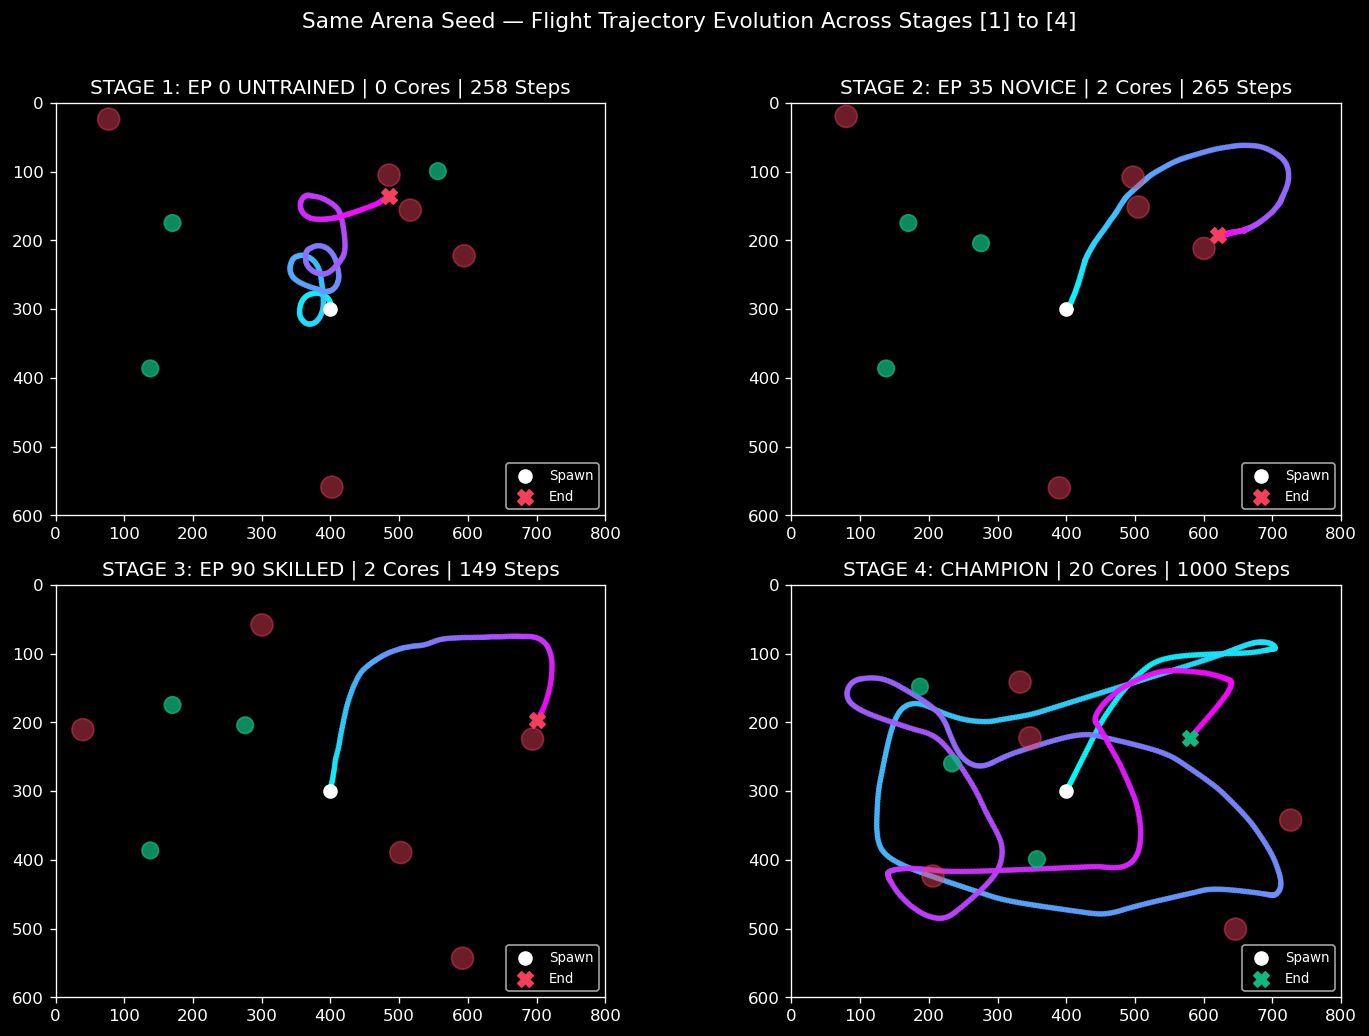

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5))
demo_seed = 70_004

for ax, stage_idx in zip(axes.ravel(), (1, 2, 3, 4)):
    fname, label = MILESTONE_SPECS[stage_idx]
    model = DQNAgent(dqn_cfg, seed=42, device="cpu")
    model.load_checkpoint(PROJECT_ROOT / "checkpoints" / fname)
    sim = RaycastArenaEnv(cfg, seed=demo_seed)
    obs = sim.reset(seed=demo_seed)
    positions = [sim.agent.position.copy()]
    done = False
    while not done:
        act, _ = model.select_action(obs, greedy=True)
        res = sim.step(act)
        obs = res.observation
        positions.append(sim.agent.position.copy())
        done = res.terminated or res.truncated

    pts = np.stack(positions)
    t_norm = np.linspace(0.0, 1.0, len(pts))
    ax.scatter(pts[:, 0], pts[:, 1], c=t_norm, cmap="cool", s=6, alpha=0.85)
    ax.scatter([pts[0, 0]], [pts[0, 1]], color="white", s=60, zorder=5, label="Spawn")
    ax.scatter([pts[-1, 0]], [pts[-1, 1]], color="#f43f5e" if res.terminated else "#10b981", marker="X", s=85, zorder=6, label="End")
    for haz in sim.hazards:
        ax.add_patch(plt.Circle(haz, cfg.hazard_radius, color="#f43f5e", alpha=0.45))
    for core in sim.cores:
        ax.add_patch(plt.Circle(core, cfg.core_radius, color="#10b981", alpha=0.75))

    ax.set_xlim(0, cfg.width)
    ax.set_ylim(cfg.height, 0)
    ax.set_aspect("equal")
    ax.set_title(f"{label} | {sim.episode_cores} Cores | {sim.step_count} Steps")
    ax.legend(loc="lower right", fontsize=8)

plt.suptitle("Same Arena Seed — Flight Trajectory Evolution Across Stages [1] to [4]", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()